# 04 - Modelado: es_incapacitante (Hito 2)

Compara 5 algoritmos de clasificación para predecir `es_incapacitante`
sobre la población aprobada en `reports/estrategia_data_preparation.md`
(histórico 2019-2022, 564 filas). El notebook solo importa y muestra: la
lógica de preparación vive en `src/prepare.py` y la de modelado en
`src/model.py` (ver CLAUDE.md).

Objetivo del README (sección 2): recall de al menos 0.70 sobre la clase
no incapacitante (minoritaria), superando el baseline de predecir siempre
la clase mayoritaria (ese baseline tiene recall 0 en la minoritaria).

In [1]:
import sys
import warnings
from pathlib import Path

import pandas as pd

sys.path.append(str(Path.cwd().parent))

from src.config import FIGURES_DIR, PROCESSED_DIR
from src.model import (
    afinar_con_grid,
    comparar_modelos,
    construir_cv,
    evaluar_en_test,
    graficar_comparacion_cv,
    graficar_curvas_roc,
    graficar_matriz_confusion,
)
from src.prepare import armar_grupo_evento, armar_X_y, cargar_poblacion_modelado

warnings.filterwarnings("ignore", category=FutureWarning)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)

df_historico = pd.read_csv(
    PROCESSED_DIR / "accidentes_historico_2012_2022.csv", parse_dates=["fecha_evento"]
)
for columna in ["turno", "programa", "lugar", "puesto_trabajo", "fuente_peligro",
                "actividad_realizada", "mes", "gravedad"]:
    df_historico[columna] = df_historico[columna].astype("category")

poblacion = cargar_poblacion_modelado(df_historico)
X, y = armar_X_y(poblacion)
grupos = armar_grupo_evento(poblacion)

print("Población de modelado:", poblacion.shape)
print("Distribución de y:", y.value_counts().to_dict())
print("X:", X.shape, "| columnas:", list(X.columns))

Población de modelado: (564, 29)
Distribución de y: {True: 409, False: 155}
X: (564, 8) | columnas: ['edad_anios', 'turno', 'programa', 'lugar', 'puesto_trabajo', 'fuente_peligro', 'actividad_realizada', 'mes']


## Partición train/test

80/20, estratificada por `es_incapacitante` y agrupada por evento (filas
del mismo accidente con varios trabajadores afectados van al mismo lado).
Se usa el primer pliegue de un `StratifiedGroupKFold` de 5, tal como se
acordó en la estrategia de preparación de datos.

In [2]:
cv_particion = construir_cv()
indice_train, indice_test = next(cv_particion.split(X, y, groups=grupos))

X_train, X_test = X.iloc[indice_train], X.iloc[indice_test]
y_train, y_test = y.iloc[indice_train], y.iloc[indice_test]
grupos_train = grupos.iloc[indice_train]

print("Train:", X_train.shape, y_train.value_counts().to_dict())
print("Test: ", X_test.shape, y_test.value_counts().to_dict())
print(
    "Grupos compartidos entre train y test:",
    len(set(grupos.iloc[indice_train]) & set(grupos.iloc[indice_test])),
)

Train: (451, 8) {True: 327, False: 124}
Test:  (113, 8) {True: 82, False: 31}
Grupos compartidos entre train y test: 0


## Comparación de 5 algoritmos (experimentación: búsqueda aleatoria)

Regresión Logística, KNN, SVM (RBF), Random Forest y Gradient Boosting
(`HistGradientBoostingClassifier`), cada uno con `RandomizedSearchCV`
(40 combinaciones, validación cruzada de 5 pliegues agrupada por evento,
solo sobre train). Se reportan 3 métricas; el modelo gana por recall de
la clase minoritaria, que es el objetivo fijado en el README.

In [3]:
tabla_comparacion, busquedas = comparar_modelos(X_train, y_train, grupos_train, n_iter=40)
tabla_comparacion.drop(columns="mejores_parametros")

,modelo,recall_minoritaria,f1_minoritaria,roc_auc
0,svm_rbf,0.880000,0.503260,0.806181
1,random_forest,0.782667,0.693248,0.880876
2,gradient_boosting,0.766000,0.683388,0.877754
3,regresion_logistica,0.702000,0.617898,0.847726
4,knn,0.516000,0.577251,0.796257


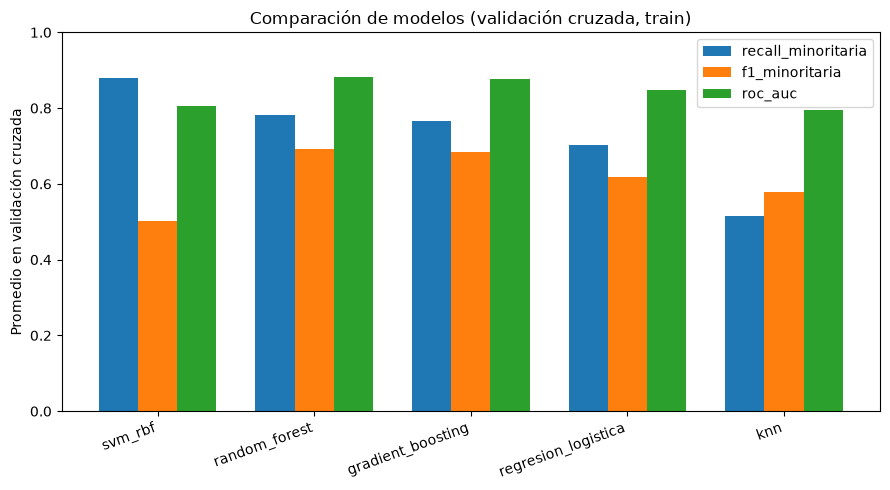

In [4]:
fig = graficar_comparacion_cv(tabla_comparacion)
fig.savefig(FIGURES_DIR / "modelado_comparacion_cv.png", dpi=100)

### Hallazgo

4 de los 5 algoritmos superan el recall de 0.70 que fija el README en
validación cruzada sobre train: SVM (0.880), Random Forest (0.783),
Gradient Boosting (0.766) y Regresión Logística (0.702, al límite). KNN
queda claramente abajo (0.516); no tiene `class_weight`, así que el
desbalance lo afecta más que a los demás.

El orden cambia si se mira F1 en vez de recall: SVM lidera en recall pero
su F1 (0.503) es el más bajo de los cuatro que cumplen el umbral, señal de
que gana recall a costa de muchos falsos positivos (predecir
incapacitante cuando no lo es). Random Forest y Gradient Boosting
mantienen un F1 bastante mejor (0.693 y 0.683) con un recall apenas menor.
Por eso se afinan los dos finalistas: el de mayor recall (SVM) y el de
mayor F1 si es distinto (Random Forest), en vez de quedarse solo con el
primer lugar de la tabla.

## Experimentación: afinamiento con GridSearchCV

Se afinan con `GridSearchCV` (grilla exhaustiva acotada alrededor de los
mejores hiperparámetros) los dos modelos más relevantes de la comparación:
el de mayor recall minoritario y, si es distinto, el de mejor F1
minoritario (para no perder de vista el balance precisión/recall).

In [5]:
ganador_recall = tabla_comparacion.iloc[0]
ganador_f1 = tabla_comparacion.sort_values("f1_minoritaria", ascending=False).iloc[0]

finalistas = {ganador_recall["modelo"]}
if ganador_f1["modelo"] != ganador_recall["modelo"]:
    finalistas.add(ganador_f1["modelo"])

print("Finalistas a afinar:", finalistas)

grillas_finas = {}
for nombre in finalistas:
    busqueda = busquedas[nombre]
    modelo_base = busqueda.best_estimator_.named_steps["modelo"]
    grillas_finas[nombre] = afinar_con_grid(
        nombre, modelo_base, busqueda.best_params_, X_train, y_train, grupos_train
    )
    print(f"\n{nombre}: mejores params afinados = {grillas_finas[nombre].best_params_}")

Finalistas a afinar: {'svm_rbf', 'random_forest'}



svm_rbf: mejores params afinados = {'modelo__C': np.float64(0.5125306745160588), 'modelo__gamma': np.float64(0.002519959333787251)}



random_forest: mejores params afinados = {'modelo__max_depth': 12, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 7, 'modelo__n_estimators': 1000}


## Evaluación final en test

Cada finalista, ya afinado, se evalúa una sola vez sobre el test
(113 filas, 31 no incapacitantes).

In [6]:
resultados_test = {}
for nombre, grilla in grillas_finas.items():
    resultados_test[nombre] = evaluar_en_test(grilla.best_estimator_, X_test, y_test)

tabla_test = pd.DataFrame(resultados_test).T.drop(columns="matriz_confusion")
tabla_test

,recall_minoritaria,recall_minoritaria_ic95,precision_minoritaria,recall_mayoritaria,precision_mayoritaria,f1_minoritaria,roc_auc
svm_rbf,0.258065,"(0.13701705906393746, 0.432461358094338)",1.0,1.0,0.780952,0.410256,0.79229
random_forest,0.806452,"(0.6371974218820453, 0.9081299163841389)",0.694444,0.865854,0.922078,0.746269,0.888867


In [7]:
for nombre, resultado in resultados_test.items():
    ic = resultado["recall_minoritaria_ic95"]
    print(f"{nombre}: recall minoritaria = {resultado['recall_minoritaria']:.3f} "
          f"(IC 95%: {ic[0]:.3f} - {ic[1]:.3f})")

svm_rbf: recall minoritaria = 0.258 (IC 95%: 0.137 - 0.432)
random_forest: recall minoritaria = 0.806 (IC 95%: 0.637 - 0.908)


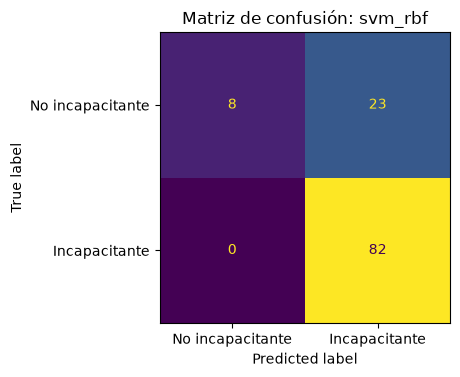

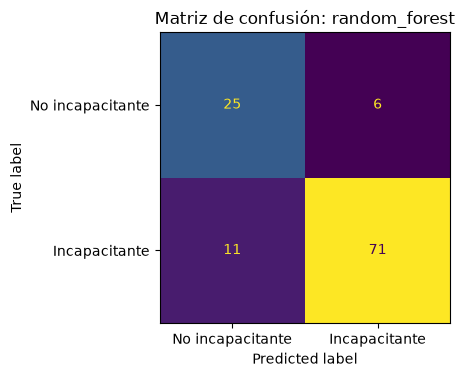

In [8]:
for nombre, resultado in resultados_test.items():
    titulo = f"Matriz de confusión: {nombre}"
    fig = graficar_matriz_confusion(resultado["matriz_confusion"], titulo=titulo)
    fig.savefig(FIGURES_DIR / f"modelado_matriz_confusion_{nombre}.png", dpi=100)

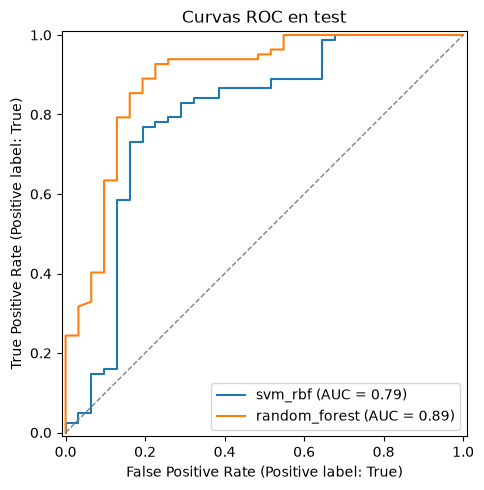

In [9]:
modelos_finales = {nombre: grilla.best_estimator_ for nombre, grilla in grillas_finas.items()}
fig = graficar_curvas_roc(modelos_finales, X_test, y_test)
fig.savefig(FIGURES_DIR / "modelado_curvas_roc.png", dpi=100)

### Hallazgo final y recomendación

**El resultado más importante de este notebook no es qué modelo ganó, es
que confiar solo en el score de validación cruzada hubiera sido un
error.** SVM, el que lideraba la comparación (recall 0.880 en CV), se
desploma a 0.258 en el test: de 31 casos no incapacitantes, solo acierta
8, porque clasifica casi todo como incapacitante (acierta las 82 filas de
esa clase, recall 1.0, pero sin distinguir nada). Es un caso de
sobreajuste a los pliegues de validación cruzada, agravado porque el
desbalance deja muy pocos casos de la clase minoritaria en cada pliegue.

Random Forest, en cambio, se mantiene estable: 0.783 en validación
cruzada y 0.806 en test (de 31 no incapacitantes, acierta 25; de 93
incapacitantes, acierta 71), con un intervalo de confianza del 95% de
0.637 a 0.908. Precisión de la clase minoritaria 0.694, F1 0.746 y
AUC-ROC 0.889.

**Recomendación: Random Forest** (`max_depth=12`, `max_features=sqrt`,
`min_samples_leaf=7`, `n_estimators=1000`). Cumple el objetivo de recall
del README con un balance razonable de precisión, y su desempeño en CV y
en test es consistente, a diferencia de SVM. No se recomienda SVM pese a
su score más alto en la comparación inicial.

## Limitaciones y próximos pasos

- **Muestra chica en la clase minoritaria**: el test tiene solo 31 casos
  no incapacitantes; el intervalo de confianza del recall de Random
  Forest (0.637 a 0.908) es amplio. Antes de usar este modelo para
  priorizar casos reales, conviene repetir la evaluación con más datos.
- **`experiencia_puesto_meses`, `sexo`, `area_responsabilidad` y `anio`
  quedan fuera de X** (ver estrategia de preparación de datos) porque su
  disponibilidad depende de la clase objetivo en 2019-2022. Si se suma el
  año 2024, vale la pena revisar si esa limitación se mantiene.
- **Una sola partición train/test**: con 564 filas, el resultado puede
  cambiar algo con otra semilla. Un próximo paso razonable es repetir la
  partición con varias semillas y reportar el rango de recall obtenido,
  no un solo número.
- **Texto libre no usado**: `descripcion_accidente` no entra al modelo
  (fuera de alcance de esta fase, ver README sección 5). Podría aportar
  señal adicional en una fase futura con procesamiento de texto.
- **Siguiente paso natural**: sumar 2024 al entrenamiento (ver
  Pendientes y próximos pasos en la wiki), que aporta más casos reales de
  la clase minoritaria y permitiría una validación con un test más
  grande.